# 03 — Exploratory Data Analysis (PySpark + SparkSQL)

## Objective
Understand what drives claim FREQUENCY and claim SEVERITY separately,
check whether a Tweedie model is justified for this target, and set
the feature plan for Notebook 04.

## Core Questions
1. How concentrated is the claim cost? (how heavy is the tail)
2. What drives whether a policy claims? (frequency)
3. What drives how much a claim costs? (severity)
4. Does claim_amount follow a Tweedie variance law, and what power p?
5. Which segments are mispriced relative to the portfolio?
6. How good is today's premium as a risk ranking? (the baseline to beat)

## Decomposition used throughout
E[claim_amount] = P(claim) x E[amount | claim]
                = frequency x severity
Tweedie regression models this product directly; the two-part model
fits each factor separately.

## Leakage Reminder
EDA may look at claim_type, claim_month and settlement_days to
UNDERSTAND severity. None of them can be a feature, because they only
exist after an accident. The leakage map from Notebook 02 still holds.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import json
import os
import warnings
warnings.filterwarnings("ignore")

os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"]        = r"C:\hadoop\bin;" + os.environ["PATH"]

JAR_PATH   = os.path.abspath("../jars/sqlite-jdbc-3.45.1.0.jar")
PROCESSED  = "../data/processed"
LOCAL_TEMP = os.path.abspath("../data/spark_temp")
os.makedirs(LOCAL_TEMP, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("Insurance_EDA")
    .master("local[2]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.extraClassPath", JAR_PATH)
    .config("spark.executor.extraClassPath", JAR_PATH)
    .config("spark.local.dir", LOCAL_TEMP)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

def read_csv(name):
    return (spark.read.option("header", "true")
            .option("inferSchema", "true")
            .csv(f"{PROCESSED}/{name}"))

policyholders = read_csv("policyholders_clean.csv")
vehicles      = read_csv("vehicles_clean.csv")
policies      = read_csv("policies_clean.csv")
claims        = read_csv("claims_clean.csv")
labels        = read_csv("labels_clean.csv")

# Policy-level table: ONE row per policy (the modeling grain)
policy_base = (
    policies
    .join(policyholders,        on="policyholder_id", how="inner")
    .join(vehicles.drop("idv"), on="policyholder_id", how="inner")
    .join(labels,               on="policy_id",       how="inner")
)

# Claimant-level table: one row per claim, with policy features attached
claimants = (
    policy_base.filter(F.col("has_claim") == 1)
    .join(claims.select("policy_id", "claim_type", "claim_month",
                        "settlement_days", "was_capped_at_idv",
                        "is_fraud_suspected"),
          on="policy_id", how="inner")
    .withColumn("claim_to_idv", F.col("claim_amount") / F.col("idv"))
)

policy_base.cache()
claimants.cache()
policy_base.createOrReplaceTempView("policy_base")
claimants.createOrReplaceTempView("claimants")

n_policies  = policy_base.count()
n_claimants = claimants.count()
n_distinct  = policy_base.select("policy_id").distinct().count()

print("Data loaded and joined ✅")
print(f"  policy_base rows      : {n_policies:>8,}  (NB02 final: 97,978)")
print(f"  distinct policy_ids   : {n_distinct:>8,}  (must equal rows: 1:1 joins)")
print(f"  claimants rows        : {n_claimants:>8,}  (expect 35,749)")
print(f"  claim rate            : {n_claimants / n_policies * 100:.4f}%  "
      f"(NB02 final: 36.4868%)")
print(f"  columns in policy_base: {len(policy_base.columns)}")

Data loaded and joined ✅
  policy_base rows      :   97,978  (NB02 final: 97,978)
  distinct policy_ids   :   97,978  (must equal rows: 1:1 joins)
  claimants rows        :   35,749  (expect 35,749)
  claim rate            : 36.4868%  (NB02 final: 36.4868%)
  columns in policy_base: 47


EDA SECTION 1 — ANATOMY OF THE TARGET

Frequency x Severity decomposition:
  Frequency  P(claim)            :      36.49%
  Severity   E[amount | claim]   : ₹     218,684
  Product                        : ₹      79,791
  Pure premium E[claim_amount]   : ₹      79,791  (must match the product)

Severity distribution (claimants only):
  Median ₹    41,538 | P90 ₹    497,304 | P99 ₹   3,011,000 | Max ₹  10,698,952
  Mean / Median = 5.3x

Cost concentration (claims sorted largest first):
  top  1% of claims =  18.2% of total claim cost
  top  5% of claims =  50.8% of total claim cost
  top 10% of claims =  66.2% of total claim cost
  top 20% of claims =  81.7% of total claim cost
  top 50% of claims =  96.7% of total claim cost

Severity bands — share of claim COUNT vs share of claim COST:
  Band         Claims  % Claims   % Cost
  <10K          7,912     22.1%     0.4%
  10K-50K      11,237     31.4%     3.6%
  50K-2L        8,530     23.9%    11.6%
  2L-10L        6,354     17.8%    34.

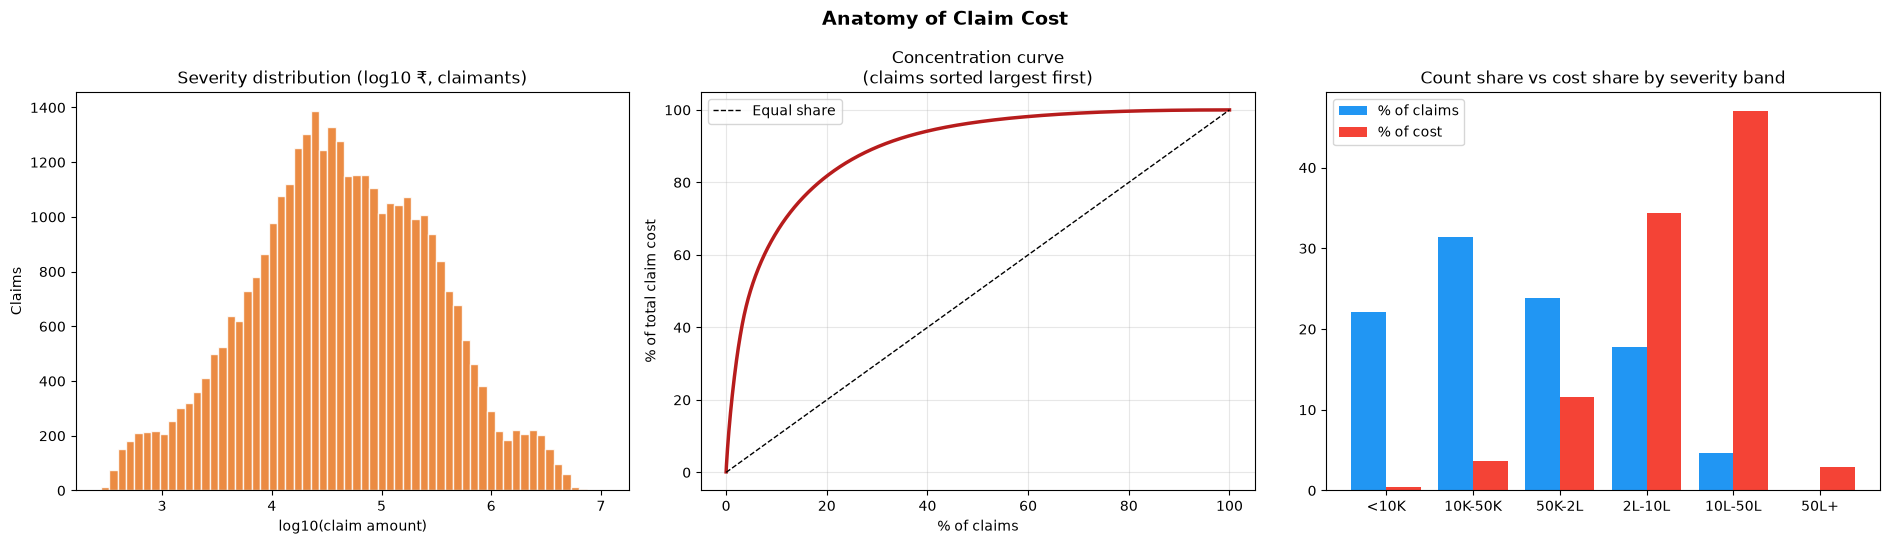

In [2]:
print("EDA SECTION 1 — ANATOMY OF THE TARGET\n")

FINDINGS = {}

freq = n_claimants / n_policies
sev = claimants.agg(
    F.avg("claim_amount").alias("mean"),
    F.percentile_approx("claim_amount", 0.5,  10000).alias("median"),
    F.percentile_approx("claim_amount", 0.9,  10000).alias("p90"),
    F.percentile_approx("claim_amount", 0.99, 10000).alias("p99"),
    F.max("claim_amount").alias("max"),
).collect()[0]
pure_premium = policy_base.agg(F.avg("claim_amount")).collect()[0][0]

print("Frequency x Severity decomposition:")
print(f"  Frequency  P(claim)            : {freq*100:>10.2f}%")
print(f"  Severity   E[amount | claim]   : ₹{sev['mean']:>12,.0f}")
print(f"  Product                        : ₹{freq*sev['mean']:>12,.0f}")
print(f"  Pure premium E[claim_amount]   : ₹{pure_premium:>12,.0f}  "
      f"(must match the product)")
print(f"\nSeverity distribution (claimants only):")
print(f"  Median ₹{sev['median']:>10,.0f} | P90 ₹{sev['p90']:>11,.0f} | "
      f"P99 ₹{sev['p99']:>12,.0f} | Max ₹{sev['max']:>12,.0f}")
print(f"  Mean / Median = {sev['mean']/sev['median']:.1f}x")

# ── Cost concentration ────────────────────────────────────────
amt = (claimants.select("claim_amount").toPandas()["claim_amount"]
       .sort_values(ascending=False).values)
cum = np.cumsum(amt) / amt.sum()

print("\nCost concentration (claims sorted largest first):")
for pct in [1, 5, 10, 20, 50]:
    k = max(1, int(len(amt) * pct / 100))
    print(f"  top {pct:>2}% of claims = {cum[k-1]*100:5.1f}% of total claim cost")

bands = pd.cut(pd.Series(amt),
               bins=[0, 10_000, 50_000, 200_000, 1_000_000, 5_000_000, np.inf],
               labels=["<10K", "10K-50K", "50K-2L", "2L-10L", "10L-50L", "50L+"])
band_df = (pd.DataFrame({"band": bands, "amt": amt})
           .groupby("band", observed=True)
           .agg(claims=("amt", "size"), cost=("amt", "sum")))
band_df["pct_claims"] = band_df["claims"] / band_df["claims"].sum() * 100
band_df["pct_cost"]   = band_df["cost"]   / band_df["cost"].sum()   * 100

print("\nSeverity bands — share of claim COUNT vs share of claim COST:")
print(f"  {'Band':<10} {'Claims':>8} {'% Claims':>9} {'% Cost':>8}")
for band, r in band_df.iterrows():
    print(f"  {band:<10} {int(r['claims']):>8,} {r['pct_claims']:>8.1f}% "
          f"{r['pct_cost']:>7.1f}%")

capped = claimants.agg(
    F.sum("was_capped_at_idv").alias("n"),
    F.sum(F.when(F.col("was_capped_at_idv") == 1, F.col("claim_amount"))
           .otherwise(0)).alias("cost"),
).collect()[0]
tot_cost = float(amt.sum())
print(f"\nClaims capped at IDV in NB02: {int(capped['n']):,} "
      f"({capped['n']/n_claimants*100:.1f}% of claims, "
      f"{capped['cost']/tot_cost*100:.1f}% of cost)")

# ── Charts ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
fig.suptitle("Anatomy of Claim Cost", fontsize=14, fontweight="bold")

axes[0].hist(np.log10(amt), bins=60, color="#E87722",
             edgecolor="white", alpha=0.85)
axes[0].set_title("Severity distribution (log10 ₹, claimants)")
axes[0].set_xlabel("log10(claim amount)")
axes[0].set_ylabel("Claims")

x = np.arange(1, len(amt) + 1) / len(amt)
axes[1].plot(x * 100, cum * 100, color="#B71C1C", linewidth=2.5)
axes[1].plot([0, 100], [0, 100], "k--", linewidth=1, label="Equal share")
axes[1].set_title("Concentration curve\n(claims sorted largest first)")
axes[1].set_xlabel("% of claims")
axes[1].set_ylabel("% of total claim cost")
axes[1].legend()
axes[1].grid(alpha=0.3)

idx = np.arange(len(band_df))
axes[2].bar(idx - 0.2, band_df["pct_claims"], 0.4,
            label="% of claims", color="#2196F3")
axes[2].bar(idx + 0.2, band_df["pct_cost"], 0.4,
            label="% of cost", color="#F44336")
axes[2].set_xticks(idx)
axes[2].set_xticklabels(band_df.index)
axes[2].set_title("Count share vs cost share by severity band")
axes[2].legend()

plt.tight_layout()
plt.savefig(f"{PROCESSED}/eda_01_target_anatomy.png", dpi=130, bbox_inches="tight")
plt.show()

FINDINGS.update({
    "claim_frequency_pct" : float(freq * 100),
    "mean_severity"       : float(sev["mean"]),
    "median_severity"     : float(sev["median"]),
    "p99_severity"        : float(sev["p99"]),
    "pure_premium"        : float(pure_premium),
    "top1pct_cost_share"  : float(cum[max(1, int(len(amt) * 0.01)) - 1] * 100),
    "top10pct_cost_share" : float(cum[max(1, int(len(amt) * 0.10)) - 1] * 100),
})

EDA SECTION 2 — WHAT DRIVES CLAIM FREQUENCY



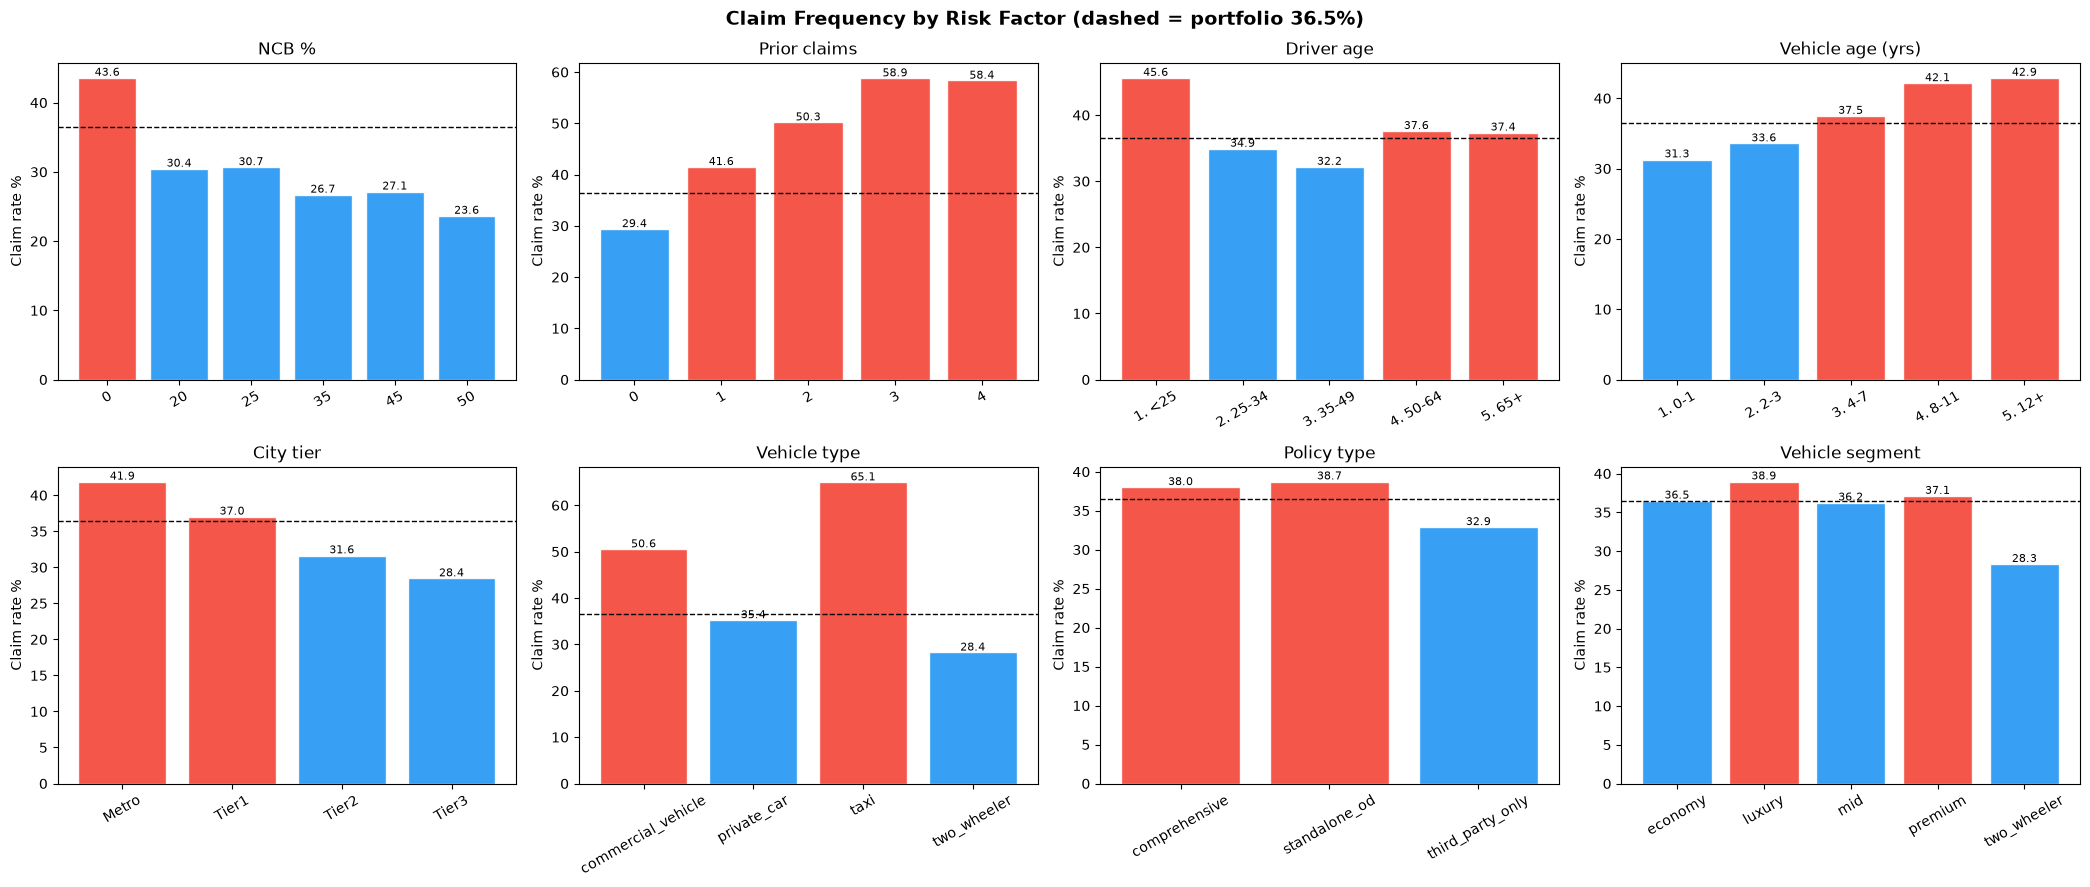

Frequency spread (groups with >= 500 policies):
  Factor                 Lowest   Highest   Ratio
  Vehicle type            28.4%     65.1%   2.29x
  Prior claims            29.4%     58.9%   2.00x
  NCB %                   23.6%     43.6%   1.84x
  City tier               28.4%     41.9%   1.47x
  Driver age              32.2%     45.6%   1.42x
  Vehicle segment         28.3%     38.9%   1.38x
  Vehicle age (yrs)       31.3%     42.9%   1.37x
  Policy type             32.9%     38.7%   1.18x

Does NCB add anything beyond prior-claims history?
+----------------+---+--------+--------------+
|history         |ncb|policies|claim_rate_pct|
+----------------+---+--------+--------------+
|has prior claims|0  |40880   |46.32         |
|no prior claims |0  |11330   |33.7          |
|no prior claims |20 |11128   |30.45         |
|no prior claims |25 |12273   |30.67         |
|no prior claims |35 |8341    |26.7          |
|no prior claims |45 |8504    |27.15         |
|no prior claims |50 |5522 

In [3]:
print("EDA SECTION 2 — WHAT DRIVES CLAIM FREQUENCY\n")

AGE_BAND = """CASE WHEN age < 25 THEN '1. <25'
                   WHEN age < 35 THEN '2. 25-34'
                   WHEN age < 50 THEN '3. 35-49'
                   WHEN age < 65 THEN '4. 50-64'
                   ELSE '5. 65+' END"""
VAGE_BAND = """CASE WHEN vehicle_age_years <= 1  THEN '1. 0-1'
                    WHEN vehicle_age_years <= 3  THEN '2. 2-3'
                    WHEN vehicle_age_years <= 7  THEN '3. 4-7'
                    WHEN vehicle_age_years <= 11 THEN '4. 8-11'
                    ELSE '5. 12+' END"""

overall_rate = n_claimants / n_policies * 100

def freq_by(expr):
    return spark.sql(f"""
        SELECT {expr}                          AS segment,
               COUNT(*)                        AS policies,
               ROUND(AVG(has_claim) * 100, 2)  AS claim_rate_pct
        FROM policy_base
        GROUP BY 1
        ORDER BY 1
    """).toPandas()

dims = [
    ("NCB %",             "CAST(ncb_percentage AS INT)"),
    ("Prior claims",      "prior_claims_count"),
    ("Driver age",        AGE_BAND),
    ("Vehicle age (yrs)", VAGE_BAND),
    ("City tier",         "city_tier"),
    ("Vehicle type",      "vehicle_type"),
    ("Policy type",       "policy_type"),
    ("Vehicle segment",   "vehicle_segment"),
]
freq_results = {label: freq_by(expr) for label, expr in dims}

fig, axes = plt.subplots(2, 4, figsize=(21, 9))
fig.suptitle(f"Claim Frequency by Risk Factor "
             f"(dashed = portfolio {overall_rate:.1f}%)",
             fontsize=14, fontweight="bold")
for ax, (label, _) in zip(axes.ravel(), dims):
    df = freq_results[label]
    colors = ["#F44336" if v > overall_rate else "#2196F3"
              for v in df["claim_rate_pct"]]
    ax.bar(df["segment"].astype(str), df["claim_rate_pct"],
           color=colors, edgecolor="white", alpha=0.9)
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_ylabel("Claim rate %")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(df["claim_rate_pct"]):
        ax.text(i, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(f"{PROCESSED}/eda_02_frequency_drivers.png", dpi=130, bbox_inches="tight")
plt.show()

# Rank the factors by how far apart their best and worst groups are
rows = []
for label, df in freq_results.items():
    d = df[df["policies"] >= 500]
    lo, hi = d["claim_rate_pct"].min(), d["claim_rate_pct"].max()
    rows.append((label, lo, hi, hi / lo))
spread = (pd.DataFrame(rows, columns=["factor", "lowest_pct", "highest_pct", "ratio"])
          .sort_values("ratio", ascending=False))

print("Frequency spread (groups with >= 500 policies):")
print(f"  {'Factor':<20} {'Lowest':>8} {'Highest':>9} {'Ratio':>7}")
for _, r in spread.iterrows():
    print(f"  {r['factor']:<20} {r['lowest_pct']:>7.1f}% {r['highest_pct']:>8.1f}% "
          f"{r['ratio']:>6.2f}x")

# NCB and prior claims are linked: confounding check
print("\nDoes NCB add anything beyond prior-claims history?")
spark.sql("""
    SELECT CASE WHEN prior_claims_count = 0 THEN 'no prior claims'
                ELSE 'has prior claims' END    AS history,
           CAST(ncb_percentage AS INT)         AS ncb,
           COUNT(*)                            AS policies,
           ROUND(AVG(has_claim) * 100, 2)      AS claim_rate_pct
    FROM policy_base
    GROUP BY 1, 2
    ORDER BY 1, 2
""").show(20, truncate=False)

FINDINGS["frequency_spread_ratio"] = {
    r["factor"]: round(float(r["ratio"]), 3) for _, r in spread.iterrows()
}

EDA SECTION 3 — WHAT DRIVES CLAIM SEVERITY

Severity by vehicle segment:
    segment  claims  mean_severity  median_severity  median_claim_to_idv
     luxury    3639      1198834.0         668623.0               0.2412
    premium    1376       282048.0         103748.0               0.1037
        mid   10988       157990.0          57576.0               0.0863
    economy   19196        69158.0          24053.0               0.0703
two_wheeler     550         6375.0           2325.0               0.0422

Severity by claim type:
         segment  claims  mean_severity  median_severity  median_claim_to_idv
           theft    2863       527433.0         276471.0               0.7123
            fire    1777       459222.0         216646.0               0.5404
natural_calamity    2526       399112.0         155343.0               0.3805
     third_party    9000       189340.0          40369.0               0.0877
      own_damage   19583       141930.0          24623.0               0.0

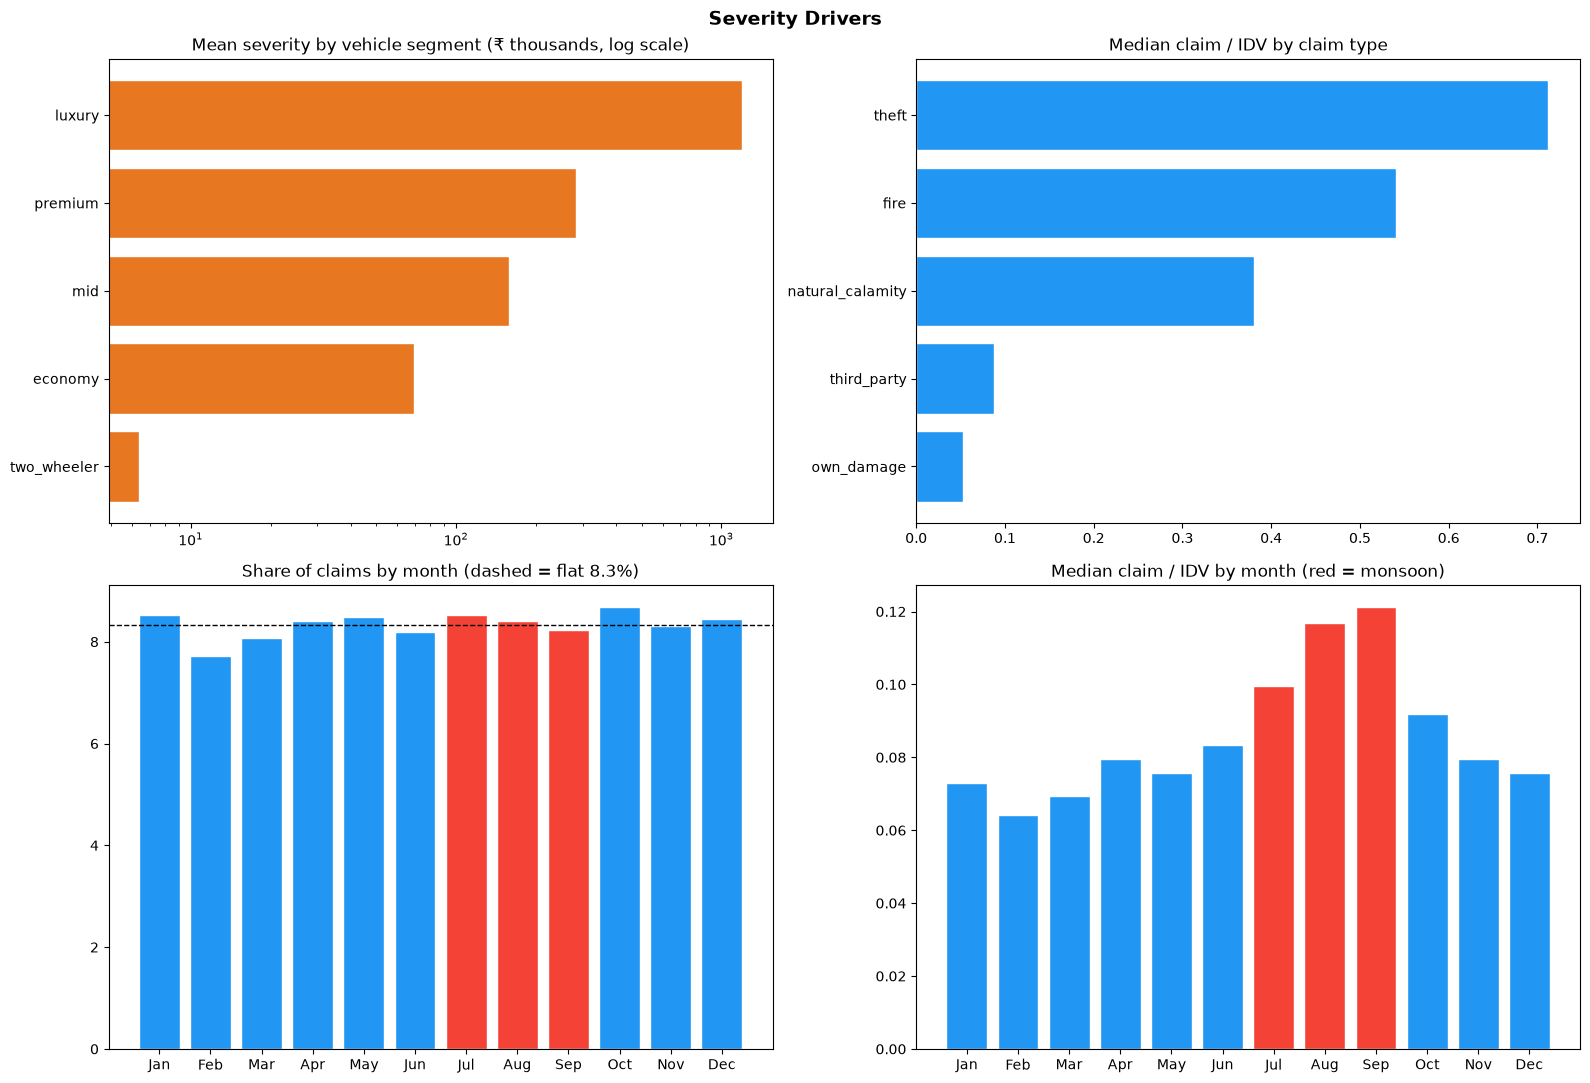

In [4]:
print("EDA SECTION 3 — WHAT DRIVES CLAIM SEVERITY\n")

def sev_by(expr):
    return spark.sql(f"""
        SELECT {expr}                                         AS segment,
               COUNT(*)                                       AS claims,
               ROUND(AVG(claim_amount), 0)                    AS mean_severity,
               ROUND(percentile_approx(claim_amount, 0.5, 1000), 0)
                                                              AS median_severity,
               ROUND(percentile_approx(claim_to_idv, 0.5, 1000), 4)
                                                              AS median_claim_to_idv
        FROM claimants
        GROUP BY 1
        ORDER BY mean_severity DESC
    """).toPandas()

seg_sev  = sev_by("vehicle_segment")
type_sev = sev_by("claim_type")

print("Severity by vehicle segment:")
print(seg_sev.to_string(index=False))
print("\nSeverity by claim type:")
print(type_sev.to_string(index=False))

lux = seg_sev.loc[seg_sev.segment == "luxury", "mean_severity"].iloc[0]
two = seg_sev.loc[seg_sev.segment == "two_wheeler", "mean_severity"].iloc[0]
print(f"\nluxury / two_wheeler mean severity = {lux/two:,.0f}x")
print("claim_to_idv removes the vehicle-value effect: compare it across")
print("segments to see what is left once price level is factored out.")

# ── Generator hypotheses 2 and 3 ──────────────────────────────
print("\n" + "=" * 70)
print("GENERATOR CHECK — policy type x claim type\n")
spark.sql("""
    SELECT policy_type, claim_type,
           COUNT(*)                                         AS claims,
           ROUND(AVG(claim_amount), 0)                      AS mean_severity,
           ROUND(percentile_approx(claim_to_idv, 0.5, 1000), 4)
                                                            AS median_claim_to_idv
    FROM claimants
    GROUP BY 1, 2
    ORDER BY 1, 2
""").show(20, truncate=False)

tp = claimants.filter(F.col("policy_type") == "third_party_only")
tp_total  = tp.count()
tp_non_tp = tp.filter(F.col("claim_type") != "third_party").count()
print(f"Third-party-only policies with a NON-third-party claim: "
      f"{tp_non_tp:,} of {tp_total:,} ({tp_non_tp/max(tp_total,1)*100:.1f}%)")
print("In real motor insurance this is 0%: TP-only has no own-damage cover.")
print("Compare median_claim_to_idv for third_party vs own_damage on")
print("comprehensive policies. If they match, severity_mult was never applied.")

# ── Seasonality: frequency vs severity ────────────────────────
print("\n" + "=" * 70)
print("SEASONALITY — frequency vs severity by claim month\n")
monthly = spark.sql("""
    SELECT claim_month,
           COUNT(*)                                          AS claims,
           ROUND(AVG(claim_amount), 0)                       AS mean_severity,
           ROUND(percentile_approx(claim_to_idv, 0.5, 1000), 4)
                                                             AS median_claim_to_idv
    FROM claimants
    GROUP BY 1
    ORDER BY 1
""").toPandas()
monthly["pct_of_claims"] = monthly["claims"] / monthly["claims"].sum() * 100
print(monthly.to_string(index=False))

is_m = monthly["claim_month"].isin([7, 8, 9])
monsoon_share = monthly.loc[is_m, "claims"].sum() / monthly["claims"].sum() * 100
sev_ratio = (monthly.loc[is_m, "median_claim_to_idv"].mean()
             / monthly.loc[~is_m, "median_claim_to_idv"].mean())
print(f"\nMonsoon (Jul-Sep) share of claims : {monsoon_share:.1f}%  (flat would be 25.0%)")
print(f"Monsoon median claim/IDV vs rest  : {sev_ratio:.2f}x")
print("Claim counts are not normalised by policies in force per month;")
print("the design makes that roughly even, so treat small gaps as noise.")

# ── Charts ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Severity Drivers", fontsize=14, fontweight="bold")

axes[0][0].barh(seg_sev["segment"], seg_sev["mean_severity"] / 1000,
                color="#E87722", edgecolor="white")
axes[0][0].set_xscale("log")
axes[0][0].set_title("Mean severity by vehicle segment (₹ thousands, log scale)")
axes[0][0].invert_yaxis()

axes[0][1].barh(type_sev["segment"], type_sev["median_claim_to_idv"],
                color="#2196F3", edgecolor="white")
axes[0][1].set_title("Median claim / IDV by claim type")
axes[0][1].invert_yaxis()

names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
mcol = ["#F44336" if m in (7, 8, 9) else "#2196F3" for m in monthly["claim_month"]]
axes[1][0].bar([names[m-1] for m in monthly["claim_month"]],
               monthly["pct_of_claims"], color=mcol, edgecolor="white")
axes[1][0].axhline(100 / 12, color="black", linestyle="--", linewidth=1)
axes[1][0].set_title("Share of claims by month (dashed = flat 8.3%)")

axes[1][1].bar([names[m-1] for m in monthly["claim_month"]],
               monthly["median_claim_to_idv"], color=mcol, edgecolor="white")
axes[1][1].set_title("Median claim / IDV by month (red = monsoon)")

plt.tight_layout()
plt.savefig(f"{PROCESSED}/eda_03_severity_drivers.png", dpi=130, bbox_inches="tight")
plt.show()

FINDINGS.update({
    "luxury_vs_two_wheeler_severity_x": float(lux / two),
    "tp_only_non_tp_claim_pct"        : float(tp_non_tp / max(tp_total, 1) * 100),
    "monsoon_claim_share_pct"         : float(monsoon_share),
    "monsoon_severity_ratio"          : float(sev_ratio),
})

EDA SECTION 4 — DOES CLAIM AMOUNT FOLLOW A TWEEDIE VARIANCE LAW?


A Tweedie variable has Var(Y) = phi * mean^p.
  p = 1      Poisson-like (counts, no heavy tail)
  1 < p < 2  compound Poisson-Gamma: a spike at zero plus a skewed
             positive part. This is the insurance case.
  p = 2      Gamma: heavier tail, no zeros
We estimate p from the data: group policies into segments, compute each
segment's mean and variance of claim_amount, and regress log(var) on
log(mean). The slope is the estimate of p.

Segments total: 299 | used (n >= 300): 76

Estimated Tweedie power p = 1.67   (bootstrap 95% over segments: 1.62 to 1.72)
Reading: inside the 1-2 compound Poisson-Gamma range.
Caveats: segments mix different IDV levels, which inflates the
variance and biases p upward. The bootstrap resamples segments,
not claims, so it ignores the noise from a few huge claims.
We will choose p by cross-validated deviance in Notebook 05.


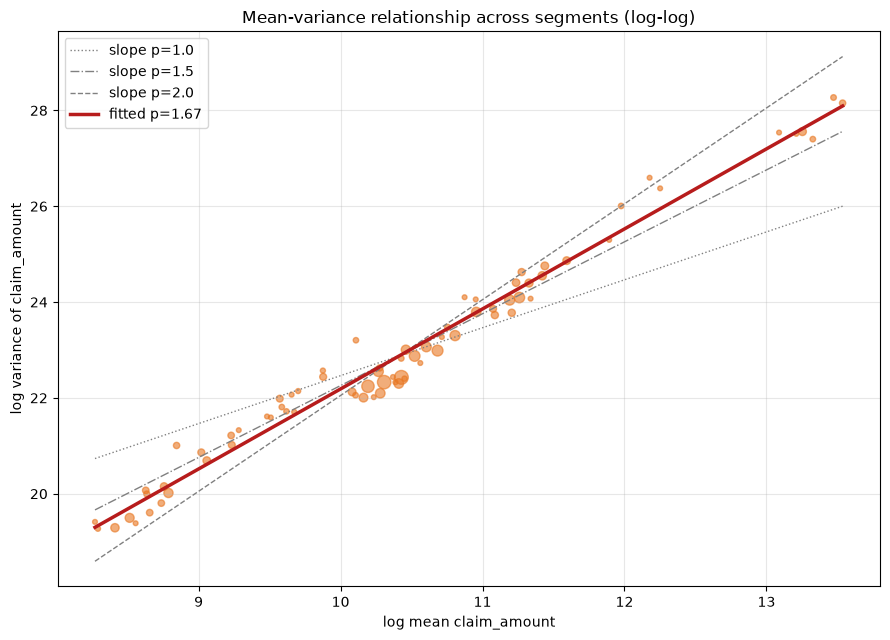

In [5]:
print("EDA SECTION 4 — DOES CLAIM AMOUNT FOLLOW A TWEEDIE VARIANCE LAW?\n")
print("""
A Tweedie variable has Var(Y) = phi * mean^p.
  p = 1      Poisson-like (counts, no heavy tail)
  1 < p < 2  compound Poisson-Gamma: a spike at zero plus a skewed
             positive part. This is the insurance case.
  p = 2      Gamma: heavier tail, no zeros
We estimate p from the data: group policies into segments, compute each
segment's mean and variance of claim_amount, and regress log(var) on
log(mean). The slope is the estimate of p.
""")

group_stats = spark.sql(f"""
    SELECT vehicle_segment, policy_type, city_tier,
           {VAGE_BAND}                 AS vehicle_age_band,
           COUNT(*)                    AS n,
           AVG(claim_amount)           AS mean_y,
           VARIANCE(claim_amount)      AS var_y
    FROM policy_base
    GROUP BY 1, 2, 3, 4
""").toPandas()

g = group_stats[(group_stats["n"] >= 300)
                & (group_stats["mean_y"] > 0)
                & (group_stats["var_y"] > 0)].copy()
print(f"Segments total: {len(group_stats)} | used (n >= 300): {len(g)}")

if len(g) < 20:
    print("⚠️ Too few segments for a stable estimate — widen the groups.")
else:
    x = np.log(g["mean_y"].values)
    y = np.log(g["var_y"].values)
    p_hat, intercept = np.polyfit(x, y, 1)

    rng = np.random.default_rng(42)
    boots = []
    for _ in range(1000):
        i = rng.integers(0, len(g), len(g))
        boots.append(np.polyfit(x[i], y[i], 1)[0])
    lo, hi = np.percentile(boots, [2.5, 97.5])

    print(f"\nEstimated Tweedie power p = {p_hat:.2f}   "
          f"(bootstrap 95% over segments: {lo:.2f} to {hi:.2f})")
    if p_hat < 1.0:
        verdict = "below 1: unusual. Check the segment definitions."
    elif p_hat <= 2.0:
        verdict = "inside the 1-2 compound Poisson-Gamma range."
    else:
        verdict = ("above 2: heavier-tailed than Gamma. A Tweedie model "
                   "would be near its limit, so the two-part model needs "
                   "a serious look.")
    print(f"Reading: {verdict}")
    print("Caveats: segments mix different IDV levels, which inflates the")
    print("variance and biases p upward. The bootstrap resamples segments,")
    print("not claims, so it ignores the noise from a few huge claims.")
    print("We will choose p by cross-validated deviance in Notebook 05.")

    fig, ax = plt.subplots(figsize=(9, 6.5))
    ax.scatter(x, y, s=np.clip(g["n"] / 40, 12, 140), alpha=0.6, color="#E87722")
    cx, cy = x.mean(), y.mean()
    xs = np.linspace(x.min(), x.max(), 50)
    for pp, ls in [(1.0, ":"), (1.5, "-."), (2.0, "--")]:
        ax.plot(xs, cy + pp * (xs - cx), color="gray", linestyle=ls,
                linewidth=1, label=f"slope p={pp}")
    ax.plot(xs, intercept + p_hat * xs, color="#B71C1C", linewidth=2.5,
            label=f"fitted p={p_hat:.2f}")
    ax.set_title("Mean-variance relationship across segments (log-log)")
    ax.set_xlabel("log mean claim_amount")
    ax.set_ylabel("log variance of claim_amount")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{PROCESSED}/eda_04_tweedie_power.png", dpi=130, bbox_inches="tight")
    plt.show()

    FINDINGS.update({"tweedie_p_hat": float(p_hat),
                     "tweedie_p_ci_low": float(lo),
                     "tweedie_p_ci_high": float(hi),
                     "tweedie_segments_used": int(len(g))})

In [6]:
print("EDA SECTION 5 — WHO IS UNDERPRICED, AND HOW GOOD IS TODAY'S PREMIUM?\n")

overall_lr = spark.sql(
    "SELECT SUM(claim_amount) / SUM(total_premium) * 100 AS lr FROM policy_base"
).collect()[0][0]
print(f"Portfolio loss ratio: {overall_lr:.1f}% (a generator calibration artifact,")
print("so we compare segments to the portfolio instead of to 100%).\n")

def relativity(expr, label):
    df = spark.sql(f"""
        SELECT {expr}                                           AS segment,
               COUNT(*)                                         AS policies,
               ROUND(AVG(has_claim) * 100, 2)                   AS freq_pct,
               ROUND(SUM(claim_amount) / COUNT(*), 0)           AS pure_premium,
               ROUND(AVG(total_premium), 0)                     AS avg_premium,
               SUM(claim_amount) / NULLIF(SUM(total_premium), 0) * 100
                                                                AS loss_ratio
        FROM policy_base
        GROUP BY 1
        ORDER BY 1
    """).toPandas()
    df["rel_loss_ratio"] = (df["loss_ratio"] / overall_lr).round(2)
    df.insert(0, "dimension", label)
    return df

rel = pd.concat([
    relativity("vehicle_segment",              "Vehicle segment"),
    relativity("policy_type",                  "Policy type"),
    relativity("city_tier",                    "City tier"),
    relativity("CAST(ncb_percentage AS INT)",  "NCB %"),
    relativity(AGE_BAND,                       "Driver age"),
    relativity(VAGE_BAND,                      "Vehicle age"),
], ignore_index=True)

print("rel_loss_ratio = segment loss ratio / portfolio loss ratio")
print("  > 1.25 underpriced vs the portfolio | < 0.80 overpriced\n")
print(f"  {'Dimension':<16} {'Segment':<18} {'Policies':>9} {'Freq%':>7} "
      f"{'PurePrem':>10} {'AvgPrem':>9} {'RelLR':>6}")
last = None
for _, r in rel.iterrows():
    if last is not None and r["dimension"] != last:
        print()
    last = r["dimension"]
    flag = ("  <- underpriced" if r["rel_loss_ratio"] > 1.25 else
            "  <- overpriced"  if r["rel_loss_ratio"] < 0.80 else "")
    print(f"  {r['dimension']:<16} {str(r['segment']):<18} {int(r['policies']):>9,} "
          f"{r['freq_pct']:>6.1f}% {r['pure_premium']:>10,.0f} "
          f"{r['avg_premium']:>9,.0f} {r['rel_loss_ratio']:>6.2f}{flag}")

# ── Premium as a risk ranking: the baseline to beat ───────────
print("\n" + "=" * 70)
print("BASELINE — how well does the current premium rank risk?\n")

def gini(actual, score):
    """Normalised-Gini building block: rank by score (ascending), then see
    how much of the actual loss falls in the high-score tail."""
    a = np.asarray(actual, dtype=float)
    s = np.asarray(score,  dtype=float)
    a = a[np.lexsort((np.arange(len(s)), s))]
    cum = np.insert(np.cumsum(a) / a.sum(), 0, 0.0)
    area = ((cum[:-1] + cum[1:]) / 2).sum() / (len(cum) - 1)
    return 1 - 2 * area

bp = policy_base.select("claim_amount", "total_premium").toPandas()
g_prem    = gini(bp["claim_amount"], bp["total_premium"])
g_perfect = gini(bp["claim_amount"], bp["claim_amount"])
print(f"  Gini of premium ranking  : {g_prem:.4f}")
print(f"  Gini of perfect ranking  : {g_perfect:.4f}")
print(f"  Normalised Gini (premium): {g_prem/g_perfect:.4f}")
print("\nThis is the insurer's own price used as a risk score. The model")
print("must beat it, or the ML adds nothing. It plays the same role as the")
print("app ETA in the ETA project and income-based RM assignment in CLV.")

FINDINGS.update({"premium_gini": float(g_prem),
                 "premium_gini_normalised": float(g_prem / g_perfect),
                 "portfolio_loss_ratio_pct": float(overall_lr)})

EDA SECTION 5 — WHO IS UNDERPRICED, AND HOW GOOD IS TODAY'S PREMIUM?

Portfolio loss ratio: 407.2% (a generator calibration artifact,
so we compare segments to the portfolio instead of to 100%).

rel_loss_ratio = segment loss ratio / portfolio loss ratio
  > 1.25 underpriced vs the portfolio | < 0.80 overpriced

  Dimension        Segment             Policies   Freq%   PurePrem   AvgPrem  RelLR
  Vehicle segment  economy               52,638   36.5%     25,221    10,795   0.57  <- overpriced
  Vehicle segment  luxury                 9,344   38.9%    466,883    73,070   1.57  <- underpriced
  Vehicle segment  mid                   30,340   36.2%     57,218    18,590   0.76  <- overpriced
  Vehicle segment  premium                3,712   37.1%    104,552    27,487   0.93
  Vehicle segment  two_wheeler            1,944   28.3%      1,804     1,360   0.33  <- overpriced

  Policy type      comprehensive         63,841   38.0%    103,408    20,267   1.25
  Policy type      standalone_od    

EDA SECTION 6 — NUMERIC ASSOCIATIONS (SPEARMAN)

Spearman uses ranks, so one ₹1 crore claim cannot dominate the way it
would in a Pearson coefficient on this heavy-tailed target.

  Feature                      freq    (has_claim)  pure    (claim_amount)    severity (claimants)   claim/IDV (claimants)
  prior_claims_count                         0.189                   0.180                  -0.013                  -0.010
  total_premium                              0.113                   0.176                   0.444                   0.165
  tp_premium                                 0.159                   0.159                   0.034                   0.006
  ncb_percentage                            -0.159                  -0.152                   0.011                   0.009
  engine_cc                                  0.078                   0.098                   0.155                   0.064
  idv                                       -0.009                   0.068        

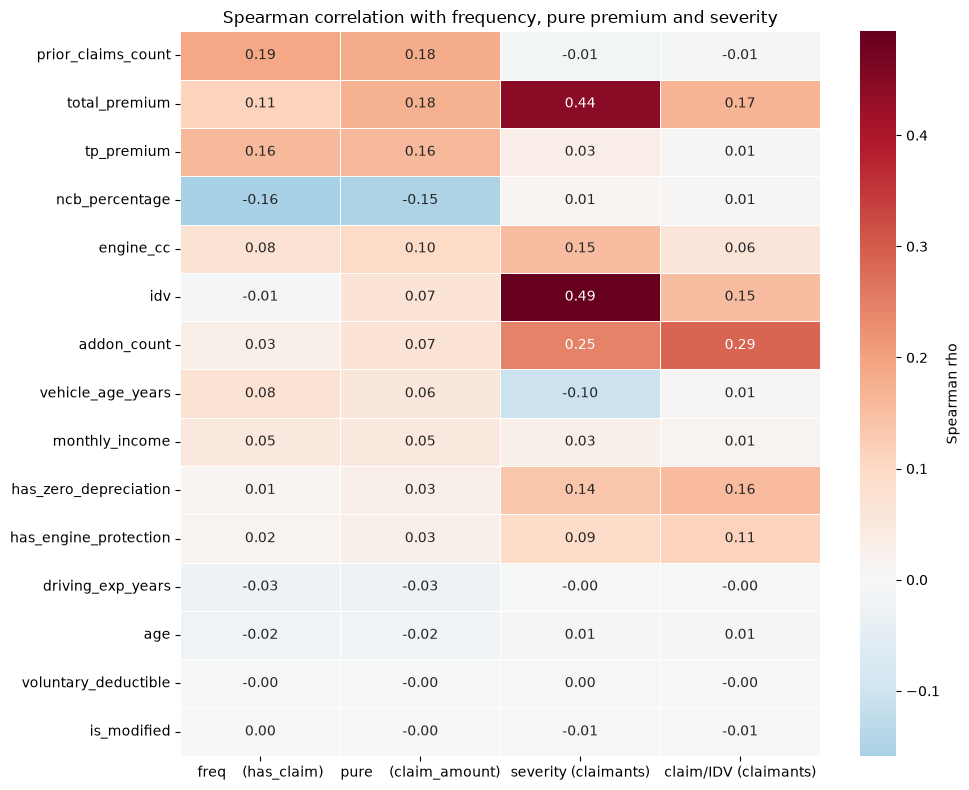

In [7]:
print("EDA SECTION 6 — NUMERIC ASSOCIATIONS (SPEARMAN)\n")
print("Spearman uses ranks, so one ₹1 crore claim cannot dominate the way it")
print("would in a Pearson coefficient on this heavy-tailed target.\n")

num_cols = [
    "age", "driving_exp_years", "monthly_income", "prior_claims_count",
    "ncb_percentage", "vehicle_age_years", "engine_cc", "idv",
    "total_premium", "tp_premium", "voluntary_deductible", "addon_count",
    "has_zero_depreciation", "has_engine_protection", "is_modified",
]

pdf = policy_base.select(num_cols + ["has_claim", "claim_amount"]).toPandas()
cdf = claimants.select(num_cols + ["claim_amount", "claim_to_idv"]).toPandas()

rho = pd.DataFrame({
    "freq    (has_claim)"     : pdf[num_cols].corrwith(pdf["has_claim"],    method="spearman"),
    "pure    (claim_amount)"  : pdf[num_cols].corrwith(pdf["claim_amount"], method="spearman"),
    "severity (claimants)"    : cdf[num_cols].corrwith(cdf["claim_amount"], method="spearman"),
    "claim/IDV (claimants)"   : cdf[num_cols].corrwith(cdf["claim_to_idv"], method="spearman"),
})
rho = rho.sort_values("pure    (claim_amount)", key=abs, ascending=False)

print(f"  {'Feature':<24}" + "".join(f"{c:>24}" for c in rho.columns))
for feat, r in rho.iterrows():
    print(f"  {feat:<24}" + "".join(f"{v:>24.3f}" for v in r.values))

cm = pdf[num_cols].corr(method="spearman")
pairs = [(a, b, cm.loc[a, b])
         for i, a in enumerate(num_cols) for b in num_cols[i + 1:]
         if abs(cm.loc[a, b]) >= 0.8]
print("\nRedundant feature pairs (|Spearman| >= 0.8):")
if pairs:
    for a, b, v in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {a:<22} ~ {b:<22} {v:>6.3f}")
else:
    print("  none")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(rho, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
            linewidths=0.5, cbar_kws={"label": "Spearman rho"})
ax.set_title("Spearman correlation with frequency, pure premium and severity")
plt.tight_layout()
plt.savefig(f"{PROCESSED}/eda_05_spearman.png", dpi=130, bbox_inches="tight")
plt.show()

FINDINGS["top_features_pure_premium"] = {
    k: round(float(v), 3)
    for k, v in rho["pure    (claim_amount)"].abs()
                   .sort_values(ascending=False).head(5).items()
}

In [8]:
def fmt(key, spec="{:,.2f}", default="not computed"):
    v = FINDINGS.get(key)
    return default if v is None else spec.format(v)

print("=" * 65)
print(" EDA COMPLETE — MEASURED FINDINGS")
print("=" * 65)
print(f"""
TARGET
  Claim frequency              : {fmt('claim_frequency_pct')}%
  Mean / median severity       : ₹{fmt('mean_severity','{:,.0f}')} / ₹{fmt('median_severity','{:,.0f}')}
  Top 1% of claims = cost share: {fmt('top1pct_cost_share')}%
  Top 10% of claims = cost share: {fmt('top10pct_cost_share')}%

TWEEDIE
  Estimated power p            : {fmt('tweedie_p_hat')}  \
(95% {fmt('tweedie_p_ci_low')} to {fmt('tweedie_p_ci_high')}, \
{fmt('tweedie_segments_used','{:.0f}')} segments)

SEVERITY
  luxury vs two-wheeler        : {fmt('luxury_vs_two_wheeler_severity_x','{:,.0f}')}x
  TP-only with non-TP claim    : {fmt('tp_only_non_tp_claim_pct')}%   (real world: 0%)

SEASONALITY
  Monsoon share of claims      : {fmt('monsoon_claim_share_pct')}%  (flat = 25%)
  Monsoon severity vs rest     : {fmt('monsoon_severity_ratio')}x

BASELINE TO BEAT
  Premium normalised Gini      : {fmt('premium_gini_normalised','{:.4f}')}
""")

print("FREQUENCY DRIVERS (ratio of highest to lowest group):")
for k, v in FINDINGS.get("frequency_spread_ratio", {}).items():
    print(f"  {k:<20} {v:>6.2f}x")

print("""
FEATURE PLAN FOR NOTEBOOK 04 (to confirm against the numbers above)
  1. Severity as a ratio: model claim_to_idv, then multiply by IDV
  2. IDV and vehicle-value features: known at quote time, not leakage
  3. NCB and prior_claims_count together, since Cell 4 tested overlap
  4. Age, vehicle-age and experience bands plus raw values
  5. Add-on and deductible features
  6. Exposure offset NOT needed (all exposure_years = 1.0)

DESIGN DECISIONS
  - Premium columns are the BASELINE, not features: the model's job is
    to price risk, and using the price as an input would be circular
  - vehicle_age_missing excluded (it encodes a generator bug, see NB02)
  - claim_type, claim_month, settlement_days, surveyor_assessment,
    is_fraud_suspected, monsoon_claim, was_capped_at_idv: post-claim,
    never features
  - claim_prob: oracle file, evaluation only in Notebook 06

GENERATOR LIMITATIONS TO DOCUMENT IN THE README
  - Loss ratio ~407% (severity calibration)
  - Monsoon effect lives in severity only (Cell 5 tests this)
  - third_party severity multiplier unused (Cell 5 tests this)
  - TP-only policies carry own-damage-type claims (Cell 5 tests this)
  - Missing vehicle age raised claim probability (NaN bug)
""")

with open(f"{PROCESSED}/eda_findings.json", "w") as f:
    json.dump(FINDINGS, f, indent=2, default=lambda o: float(o))
print("✅ eda_findings.json saved")

policy_base.unpersist()
claimants.unpersist()
print("Caches cleared ✅")

 EDA COMPLETE — MEASURED FINDINGS

TARGET
  Claim frequency              : 36.49%
  Mean / median severity       : ₹218,684 / ₹41,538
  Top 1% of claims = cost share: 18.24%
  Top 10% of claims = cost share: 66.21%

TWEEDIE
  Estimated power p            : 1.67  (95% 1.62 to 1.72, 76 segments)

SEVERITY
  luxury vs two-wheeler        : 188x
  TP-only with non-TP claim    : 74.86%   (real world: 0%)

SEASONALITY
  Monsoon share of claims      : 25.16%  (flat = 25%)
  Monsoon severity vs rest     : 1.46x

BASELINE TO BEAT
  Premium normalised Gini      : 0.6800

FREQUENCY DRIVERS (ratio of highest to lowest group):
  Vehicle type           2.29x
  Prior claims           2.00x
  NCB %                  1.84x
  City tier              1.47x
  Driver age             1.42x
  Vehicle segment        1.38x
  Vehicle age (yrs)      1.37x
  Policy type            1.18x

FEATURE PLAN FOR NOTEBOOK 04 (to confirm against the numbers above)
  1. Severity as a ratio: model claim_to_idv, then multiply by